In [1]:
using Flux
using CUDA, cuDNN
using StatsPlots
using Plots; default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging; 
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras
using MosaicViews
using NPZ
using Images

In [2]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu
    
    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end

    CUDA.allowscalar(false)  # recommended
end

[ Info: 🚀 Functional GPU detected! Setting device to CUDA.


In [3]:
include("./utils.jl")
include("./io_utils.jl")
batch_size = 200
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor_shape = (28^2, :))

(DataLoader(data::Tuple{SubArray{Bool, 2, BitMatrix, Tuple{Base.Slice{Base.OneTo{Int64}}, UnitRange{Int64}}, true}}, shuffle=true, batchsize=200), Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0])

In [4]:
global_logger(cudnn_filter);
# Create a logger that suppresses the location metadata for :info and below
# clean_logger = FormatLogger(stderr) do io, log
#     println(io, "  [ $(log.level): $(log.message)")
# end

# # Set it globally for the rest of your notebook session
# global_logger(clean_logger);

In [5]:
begin
    struct MaskedDense{T <: Real}
		weight::AbstractMatrix{T}
		bias::AbstractVector{T}
		act::Function
		mask::AbstractMatrix{Bool}
	end


	Flux.@layer MaskedDense trainable = (weight, bias)

	
	MaskedDense(in::Int, out::Int, mask; act = identity, bias = true, init = Flux.glorot_uniform) = MaskedDense(
		init(out, in),
		zeros32(out),
		act,
		mask
	)


	MaskedDense(in::Int, out::Int; act = identity, bias = true, init = Flux.glorot_uniform) = MaskedDense(in, out, fill(true, out, in); act = act, bias = bias, init = init)

    function MaskedDense(in::Int, out::Int, ms_in::AbstractVector{<:Integer}, ms_out::AbstractVector{<:Integer}; output_layer = false, act = identity, bias = true, init = Flux.glorot_uniform) 
        md = MaskedDense(in, out; act = act, bias = bias, init = init)
        set_mask!(md, ms_in, ms_out; output_layer = output_layer)
        return md
    end
    
	function (m::MaskedDense)(xs)
		W = m.weight .* m.mask
		zs = W * xs .+ m.bias
		m.act.(zs)
	end


	function register_mask!(m::MaskedDense, mask)
		m.mask .= mask
	end

    function set_mask!(m::MaskedDense, ms_in, ms_out; output_layer = false)
        set_mask!(m.mask, ms_in, ms_out; output_layer = output_layer)
    end
end

set_mask! (generic function with 1 method)

In [6]:
begin
    function set_mask!(mask::AbstractMatrix{Bool}, ms_in, ms_out; output_layer=false)
        # for i in 1:size(mask)[1]
        #     for j in 1:size(mask)[2]
        #         mask[i, j] = output_layer ? ms_out[i] > ms_in[j] : ms_out[i] >= ms_in[j]
        #     end
        # end
        for idx in CartesianIndices(mask)
            # i, j = idx[1], idx[2]
            mask[idx] = output_layer ? ms_out[idx[1]] > ms_in[idx[2]] : ms_out[idx[1]] >= ms_in[idx[2]]
        end
    end

    function produce_mask_set(total_d::Int, hidden_sizes::Vector{Int}; fixed_input_order=nothing, res_con::Bool=false)
        masks = Vector{AbstractMatrix{Bool}}(undef, length(hidden_sizes) + 1 + res_con) ## with res_con, we need one more mask
        input_order = isnothing(fixed_input_order) ? shuffle(1:total_d) : fixed_input_order
        m_in = input_order
        h_in = total_d
        for (l, h_out) in enumerate(hidden_sizes)
            m_out = rand(minimum(m_in):(total_d-1), h_out)
            mask_layer = fill(false, h_out, h_in)
            set_mask!(mask_layer, m_in, m_out)
            masks[l] = mask_layer
            m_in = m_out
            h_in = h_out
        end
        mask_out_layer = fill(false, total_d, hidden_sizes[end])
        set_mask!(mask_out_layer, m_in, input_order; output_layer=true)
        masks[end-res_con] = mask_out_layer
        if res_con
            mask_res_con = fill(false, total_d, total_d)
            set_mask!(mask_res_con, input_order, input_order; output_layer=true)
            masks[end] = mask_res_con
        end
        return masks, input_order
    end


    function create_network(d::Int, hidden_sizes::Vector{Int}; act=relu, bias=true, res_con=false, init=Flux.glorot_uniform)
        hs = [d, hidden_sizes...]
        mlp_net = []
        for l in 1:(length(hs)-1)
            layer = MaskedDense(hs[l], hs[l+1]; act=act, bias=bias, init=init)
            push!(mlp_net, layer)
        end
        push!(mlp_net, MaskedDense(hs[end], d; act=identity, bias=bias, init=init))

        if res_con
            res_net = MaskedDense(d, d; act=identity, bias=bias, init=init)
            return Parallel(+, Chain(mlp_net...), res_net)
        else
            return Chain(mlp_net...)
        end
    end

    function compute_con_matrix(mask_set, input_order, res_con::Bool)
        con = mask_set[1]'
        for m in mask_set[2:(end-res_con)]
            con = con * m'
        end

        con = res_con ? con + mask_set[end]' : con
        i_sp = sortperm(input_order)
        sorted_con = con[i_sp, i_sp]
        return sorted_con
    end

    
    function check_causal_mask(mask_set, input_order, res_con::Bool)
        sorted_con = compute_con_matrix(mask_set, input_order, res_con)
        istriu(sorted_con) && all(diag(sorted_con) .== 0)
    end




end

check_causal_mask (generic function with 1 method)

In [ ]:
begin

    struct MADE{T<:Union{Chain,Parallel}}
        d::Integer ## number of input; or input dimension
        # hidden_sizes ## hidden sizes of the hidden layers
        # input_order ## the input order: if nothing, then randomly generated
        net::T ## trainable network
        res_con::Bool ## direct connection or not
        num_masks::Int ## number of masks used in the training 
        # mask_pool::Vector{Vector{AbstractMatrix{Bool}}} ## the set of maskset pools
        mask_pool
        # input_orders::Vector{Vector{Int}}
        input_orders
        current_mask_idx::Base.RefValue{Int} # Wraps the integer in a mutable container
        cycle_mask::Bool
    end


    Flux.@layer MADE trainable = (net,)

    function MADE(d::Int=28^2, hidden_sizes::Vector{Int}=[8000]; act=relu, cycle_mask=true, bias=true, input_order=nothing, res_con=true, num_masks=1, init=Flux.glorot_uniform)
        mask_pool_with_input_orders = [produce_mask_set(d, hidden_sizes; fixed_input_order=input_order, res_con=res_con) for _ in 1:num_masks]
        mask_pool = [mask_pool_with_input_orders[i][1] for i in 1:num_masks]
        input_orders = [mask_pool_with_input_orders[i][2] for i in 1:num_masks] ## useful for sampling
        current_mask_idx = 1
        net = create_network(d, hidden_sizes; act=act, bias=bias, res_con=res_con, init=init)
        set_maskset!(net, mask_pool[current_mask_idx], res_con)
        MADE(d, net, res_con, num_masks, mask_pool, input_orders, Ref(current_mask_idx), cycle_mask)
    end

    function update_maskset!(model::MADE)
        if model.num_masks > 1
            if model.cycle_mask
                mask_idx = (model.current_mask_idx[]) % model.num_masks + 1
            else
                mask_idx = rand(1:model.num_masks)
            end
            model.current_mask_idx[] = mask_idx
            set_maskset!(model.net, model.mask_pool[mask_idx], model.res_con)
        end
    end


    function set_maskset!(net::Union{Chain,Parallel}, mask_set::Vector{Y}, res_con::Bool) where Y<:AbstractMatrix{Bool}
        if res_con
            mlp = net[1]
            res_net = net[2]
            for (li, masked_layer) in enumerate(mlp)
                register_mask!(masked_layer, mask_set[li])
            end
            register_mask!(res_net, mask_set[end])
        else
            for (li, masked_layer) in enumerate(net)
                register_mask!(masked_layer, mask_set[li])
            end
        end
    end




    function (m::MADE)(x)
        m.net(x)
    end

    function sample(model::MADE, n=1; samples_only =true)
        total_d = model.d
        n_each_mask = Int(ceil(n/model.num_masks))
        xs_all = []
        ps_all = []
        for _ in 1:model.num_masks
            # xs = BitMatrix(undef, total_d, n_each_mask) |> device
            xs = zeros(Bool, total_d, n_each_mask) |> device
            ps_mat = similar(xs, Float32) 
            mask_idx = model.current_mask_idx[]
            d_order = model.input_orders[mask_idx] |> cpu
            for d in sortperm(d_order)
                ps = σ(model(xs)[d, :])
                xs[d, :] = rand_like(ps) .< ps
                ps_mat[d, :] = ps
            end
            update_maskset!(model)
            push!(xs_all, xs)
            push!(ps_all, ps_mat)
        end
        xs_samples = hcat(xs_all...)[:, 1:n]
        if samples_only
            return xs_samples
        else
            return xs_samples, hcat(ps_all...)[:, 1:n]
        end
    end


    function fit!(model::MADE, data_loader, optim=Adam(3f-4), max_epochs=50; verbose=true, learning_rate_decay=true, validation_data=nothing, patience=Inf, every_epoch = 10)
        initial_lr = optim.eta ## initial learning rate
        if learning_rate_decay 
            total_batches_per_epoch = length(data_loader)
            total_steps = max_epochs * total_batches_per_epoch
            # 1. Calculate your steps based on your data loop
            warmup_steps = Int(ceil(0.1 * total_steps))   # e.g., 10% of your training loop
            decay_steps = total_steps - warmup_steps  # The remaining steps in your training loop
            # 2. Define the two phases
            ss = WarmupLinear(1e-6, Float64(initial_lr), warmup_steps, total_steps, CosAnneal(Float64(initial_lr), 1e-6, decay_steps))
            # 3. Combine them chronologically into a single schedule
            schedule = ParameterSchedulers.Stateful(ss)
        end
        opt = Flux.setup(optim, model)
        losses = []
        valid_loss = []
        validation_check = false
        best_model = deepcopy(model |> cpu)
        if !isnothing(validation_data)
            # Trackers for early stopping
            validation_check = true
            best_val_loss = Inf
            # To save a checkpoint of the best model
            epochs_no_improve = 0
        end
    

        @showprogress for epoch in 1:max_epochs
            for (xs,) in data_loader
                xs_gpu = xs |> device
                li, gs = Flux.withgradient(model) do m
                    # preds = m(xs_gpu)
                    -logpdf(m, xs_gpu; train=true)
                end

                Flux.update!(opt, model, gs[1])
                push!(losses, li)

                if learning_rate_decay
                    next_lr = ParameterSchedulers.next!(schedule)
                    Flux.adjust!(opt, next_lr)
                end
                if model.num_masks > 1
                    update_maskset!(model)
                end
            end

            # --- VALIDATION PHASE (End of Epoch) ---
            if validation_check
                current_val_loss = -logpdf(model, validation_data |> device)
                push!(valid_loss, current_val_loss)
                # --- EARLY STOPPING LOGIC ---
                if current_val_loss < best_val_loss
                    # New best found! Reset patience tracker and save parameters
                    best_val_loss = current_val_loss
                    best_model = deepcopy(model |> cpu) # Save snapshot
                    epochs_no_improve = 0
                else
                    # No improvement, increment counter
                    epochs_no_improve += 1
                end

                # Check if patience has run out
                if epochs_no_improve >= patience
                    # initial_lr *= 0.5
                    # Flux.adjust!(opt, eta=initial_lr)
                    @info "🛑 Early stopping triggered! No improvement for $patience epochs."
                    # println("🏆 Best Validation Loss achieved: $(round(best_val_loss, digits=5))")
                    epochs_no_improve = 0
                    break
                end
            end

            if verbose && (epoch % every_epoch) == 1
                @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
            end
        end
        return losses, valid_loss, best_model
    end


    function logpdf(model::MADE, xs; reduction=mean, train=true)
        if train
            xs_preds = model(xs)
            logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
            logL = sum(logL, dims=1)
            logL |> reduction
        else
            logpdf_test(model, xs; reduction=reduction)
        end
    end


    function logpdf_test(model::MADE, xs; reduction=mean)
        num_masks = model.num_masks
        logLiks = zeros32(num_masks, size(xs)[2])
        for m in 1:num_masks
            xs_preds = model(xs)
            logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
            logL = sum(logL, dims=1)
            logLiks[m, :] = logL[:] |> cpu
            update_maskset!(model)
        end
        logsumexp(logLiks .+ log(1.0f0/num_masks), dims=1) |> reduction
    end

    ## this is how Andrej Karpathy implement the test log likelihood, which is biased
    function logpdf_test_karpathy(model::MADE, xs; reduction=mean)
        num_masks = model.num_masks
        liks = zeros32(size(xs)[1], size(xs)[2])
        for m in 1:num_masks
            xs_preds = model(xs)
            # logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
            probs = sigmoid(xs_preds)
            pixel_likelihood = xs .* probs + (1 .- xs) .* (1 .- probs)
            # logL = sum(logL, dims=1)
            # logLiks[m, :] = logL[:]
            liks += pixel_likelihood |> cpu
            update_maskset!(model)
        end
        # logsumexp(logLiks .+ log(1/num_masks), dims=1) |> reduction
        sum(log.(liks / num_masks .+ 1f-10), dims=1) |> mean
    end
end

logpdf_test_karpathy (generic function with 1 method)

In [8]:
function compute_con_matrix(model::MADE)
    con_mats = []

    for i in 1:model.num_masks
        mat = compute_con_matrix(model.mask_pool[i], model.input_orders[i], model.res_con)
        push!(con_mats, mat)
    end
    return con_mats
end

function check_causal_mask(model::MADE)
    for i in 1:model.num_masks
        if !check_causal_mask(model.mask_pool[i], model.input_orders[i], model.res_con)
            return false
        end
    end
    return true
end

check_causal_mask (generic function with 2 methods)

In [93]:
Random.seed!(1234)
input_order = shuffle([1:28^2;])
hidden_size = 5000
made_model_one_mask = MADE(28^2, [hidden_size]; input_order = input_order, res_con = true, num_masks = 1)  |> device
losses_made_one_mask, valid_loss_one_mask, best_made_one_mask = fit!(made_model_one_mask, mnist_binary_loader, Adam(), 40; verbose =false, validation_data = mnist_binary_valid, patience = 50)

# losses_made_en, best_made_en = fit!(made_model_en, mnist_binary_loader, Adam(), 500; validation_data = mnist_binary_valid, patience =50)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:32


(Any[549.489f0, 501.81808f0, 501.88577f0, 501.82227f0, 502.5871f0, 502.06226f0, 501.49768f0, 501.03726f0, 501.8765f0, 501.06372f0  …  75.874825f0, 73.19785f0, 72.6692f0, 73.74643f0, 74.41101f0, 72.354996f0, 73.93167f0, 74.571724f0, 74.14135f0, 73.80354f0], Any[170.75522f0, 121.23485f0, 106.100525f0, 100.65334f0, 97.537476f0, 95.66019f0, 94.31649f0, 93.45512f0, 92.760414f0, 92.21309f0  …  91.52733f0, 91.55983f0, 91.57548f0, 91.59441f0, 91.602066f0, 91.5981f0, 91.60452f0, 91.60421f0, 91.60407f0, 91.60447f0], MADE{Parallel{typeof(+), Tuple{Chain{Tuple{MaskedDense{Float32}, MaskedDense{Float32}}}, MaskedDense{Float32}}}}(784, Parallel(+, Chain(MaskedDense{Float32}(Float32[-0.008419768 -0.031073704 … -0.014346604 0.0051309178; -0.011955991 -0.019363984 … 0.025113177 0.02206686; … ; 0.015188309 0.0022619986 … -0.00819218 -0.009329611; 0.021697007 -0.015123795 … -0.031663474 0.024404544], Float32[-0.123746745, 0.2630944, 0.0, -0.059069797, 0.00795255, -0.010916639, -0.13004315, 0.0073403944, 

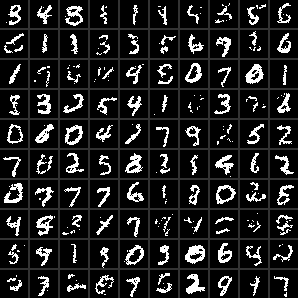

In [94]:
vec2imgs(sample(made_model_one_mask, 100); nrows=10)
# sample(made_model_one_mask, 100)[1]

In [95]:
check_causal_mask(made_model_one_mask)

true

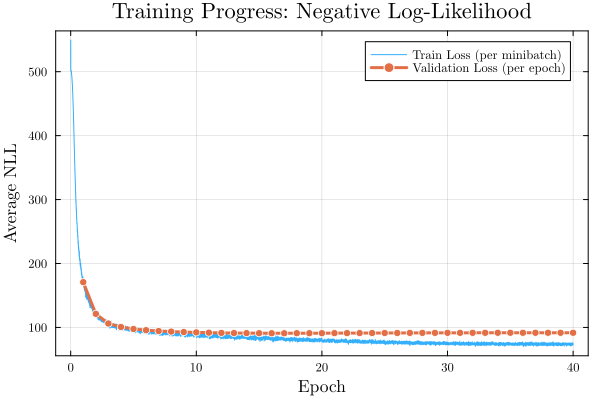

In [99]:
plot_loss_history(losses_made_one_mask, valid_loss_one_mask, mnist_binary_loader)

In [71]:
logpdf(made_model_one_mask |> device, mnist_binary_test |> device; train = false)

-90.72875f0

In [72]:
update_maskset!(made_model_one_mask)
logpdf(made_model_one_mask|> device, mnist_binary_test |> device)

-90.72875f0

In [100]:
Random.seed!(1234)
made_model_en = MADE(28^2, [8000, 8000]; act=relu, input_order=nothing, res_con=true, num_masks=20, init=Flux.kaiming_uniform) |> device
losses_made_en, valid_loss_en, best_made_en = fit!(made_model_en, mnist_binary_loader, Adam(), 50; validation_data=mnist_binary_valid, patience=30, every_epoch=20)

[ Info: Epoch 1; Loss = 237.6991
Progress:  40%|████████████████▍                        |  ETA: 0:03:29[ Info: Epoch 21; Loss = 98.6657
Progress:  80%|████████████████████████████████▊        |  ETA: 0:01:08[ Info: Epoch 41; Loss = 84.2977
Progress: 100%|█████████████████████████████████████████| Time: 0:05:26


(Any[557.4388f0, 508.0775f0, 511.10843f0, 510.18054f0, 506.61f0, 506.14197f0, 507.67065f0, 506.2313f0, 505.72632f0, 506.44366f0  …  86.54519f0, 85.61465f0, 81.86837f0, 80.84683f0, 88.58419f0, 85.43781f0, 81.554f0, 84.1009f0, 81.6977f0, 86.17721f0], Any[228.85118f0, 179.23586f0, 151.17682f0, 138.42741f0, 130.33127f0, 121.74105f0, 117.74763f0, 113.97274f0, 112.15855f0, 110.34802f0  …  92.89765f0, 92.63662f0, 92.76497f0, 92.529015f0, 92.6693f0, 92.48551f0, 92.62325f0, 92.45463f0, 92.612045f0, 92.44836f0], MADE{Parallel{typeof(+), Tuple{Chain{Tuple{MaskedDense{Float32}, MaskedDense{Float32}, MaskedDense{Float32}}}, MaskedDense{Float32}}}}(784, Parallel(+, Chain(MaskedDense{Float32}(Float32[0.0007940054 0.0582085 … -0.07341845 -0.031959068; 0.025899705 0.04749452 … 0.021898914 0.022662967; … ; 0.010228702 0.07493787 … -0.02000865 -0.016611531; -0.07730669 0.0007408923 … 0.08221244 0.07426588], Float32[0.051797837, -0.059114687, 0.08044494, -0.09858438, 0.050765183, -0.007590877, -0.00500450

In [16]:
# losses_made_cont, _ = fit!(made_model_en, mnist_binary_loader, Adam(1e-5), 500; validation_data = mnist_binary_valid, patience =50)

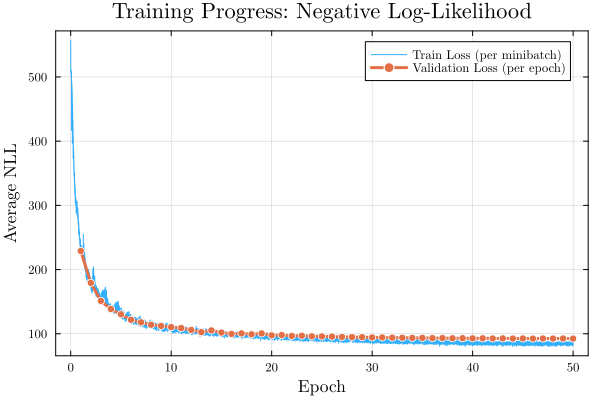

In [101]:
plot_loss_history(losses_made_en, valid_loss_en, mnist_binary_loader)

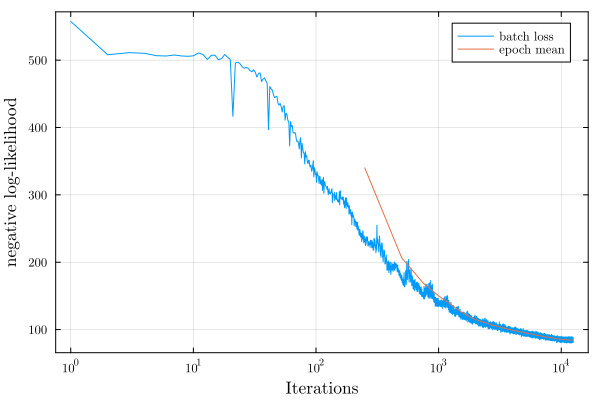

In [102]:
plot_loss(losses_made_en, length(mnist_binary_loader))

In [103]:
update_maskset!(best_made_en)
logpdf(best_made_en |> device, mnist_binary_test |> device)

-91.6778f0

In [104]:
logpdf(made_model_en |> device, mnist_binary_test |> device; train = false)

-87.439705f0

In [105]:
logpdf_test_karpathy(made_model_en |> device, mnist_binary_test |> device)

-77.67652f0

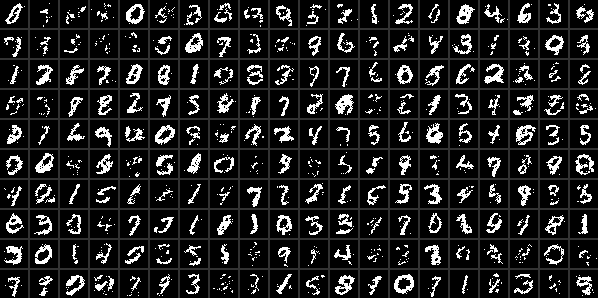

In [106]:
vec2imgs(sample(made_model_en |> device, 200); nrows=10)

In [22]:
train_loader, test_loader, valid_loader = load_mnist_data(batch_size; dtype=Bool, tensor_shape=(28*28, :))

(DataLoader(data::Tuple{SubArray{Bool, 2, BitMatrix, Tuple{Base.Slice{Base.OneTo{Int64}}, UnitRange{Int64}}, true}, Vector{Int64}}, shuffle=true, batchsize=200), DataLoader(data::Tuple{BitMatrix, Vector{Int64}}, shuffle=true, batchsize=200), DataLoader(data::Tuple{BitMatrix, Vector{Int64}}, shuffle=true, batchsize=200))

In [ ]:
Random.seed!(1234)
made_model_en_new_data = MADE(28^2, [8000, 8000]; act=relu, input_order=nothing, res_con=true, num_masks=20, init=Flux.kaiming_uniform) |> device
losses_made_en_new_data, best_made_en_new_data = fit!(made_model_en_new_data, train_loader, Adam(), 50; validation_data=valid_loader.data[1], patience=30, every_epoch=20)

[ Info: Epoch 1; Loss = 264.9713
Progress:  20%|████████▎                                |  ETA: 0:10:00[ Info: Epoch 21; Loss = 95.0166
Progress:  40%|████████████████▍                        |  ETA: 0:06:51[ Info: Epoch 41; Loss = 84.5274
Progress:  60%|████████████████████████▋                |  ETA: 0:04:02[ Info: Epoch 61; Loss = 78.8599
Progress:  72%|█████████████████████████████▌           |  ETA: 0:02:41[ Info: 🛑 Early stopping triggered! No improvement for 30 epochs.
Progress: 100%|█████████████████████████████████████████| Time: 0:06:58


(Any[557.2934f0, 506.93976f0, 510.56335f0, 510.6554f0, 506.33624f0, 505.9442f0, 507.63364f0, 507.53094f0, 506.25848f0, 508.34726f0  …  79.913536f0, 76.89224f0, 75.95233f0, 77.66894f0, 75.70908f0, 76.66693f0, 74.35497f0, 73.852844f0, 77.17474f0, 76.36102f0], MADE{Parallel{typeof(+), Tuple{Chain{Tuple{MaskedDense{Float32}, MaskedDense{Float32}, MaskedDense{Float32}}}, MaskedDense{Float32}}}}(784, Parallel(+, Chain(MaskedDense{Float32}(Float32[0.0007940054 0.0582085 … -0.07341845 -0.031959068; 0.025899705 0.04749452 … 0.021898914 0.022662967; … ; 0.010228702 0.07493787 … -0.02000865 -0.016611531; -0.07730669 0.0007408923 … 0.08221244 0.07426588], Float32[0.017546482, -0.13408184, 0.07906863, -0.20224959, 0.021945423, -0.061229292, -0.07549721, -0.1194866, -0.0024276061, 0.025786186  …  -0.18358214, 0.05904532, -0.063926615, -0.033400197, 0.040478077, -0.005563365, 0.1562798, 0.015087971, -0.19971125, -0.08783806], NNlib.relu, Bool[0 0 … 0 0; 0 0 … 0 0; … ; 1 0 … 0 1; 1 1 … 1 1]), MaskedDe

In [25]:
logpdf(made_model_en_new_data |> device, test_loader.data[1] |> device; train = false)

-87.5213f0

In [26]:
xsamples, psamples = sample(made_model_en_new_data |> device, 200; sample_data=false)

(Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Float32[4.6926942f-8 1.9512163f-8 … 1.7496034f-6 1.8538359f-6; 1.9035024f-8 2.68024f-8 … 1.0436515f-9 5.803713f-10; … ; 2.0724981f-10 7.2134065f-10 … 4.0220876f-9 6.2018013f-9; 1.9956933f-7 7.5804856f-8 … 5.7982503f-9 4.335846f-8])

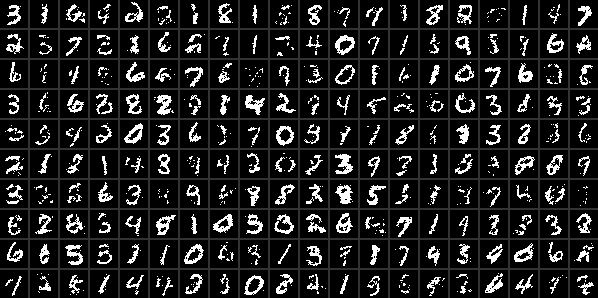

In [27]:
vec2imgs(xsamples; nrows=10) 

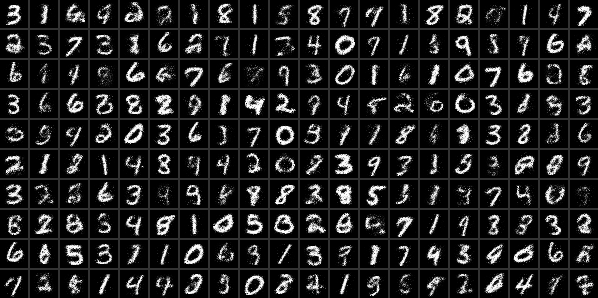

In [28]:
vec2imgs(psamples; nrows=10)

In [29]:
function _sample(model, n=1; input_order=1:(28^2))
    # xs = zeros(Bool, 28^2, n) |> device
    xs = zeros(Bool, 28^2, n) |> device

    for d in sortperm(input_order)
        # Find WHICH spatial pixel index corresponds to the current step
        # d = input_order[step]
        
        # Run the full forward pass
        logits_d = model(xs)[d, :]
        ps = σ.(logits_d)
        # Extract predictions for this specific pixel dimension across the batch
        
        # Sample and update the pixel state on the device
        xs[d, :] = rand_like(ps) .< ps
    end

    return xs 
end

function logpdf(model::Chain, xs; reduction=mean)
    xs_preds = model(xs)
    logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
    logL = sum(logL, dims=1)
    logL |> reduction
end

logpdf (generic function with 2 methods)

In [30]:
begin
    Random.seed!(1234)
    hidden_size = 28^2
    # hidden_order = sort(rand(1:28^2-1, hidden_size))
    hidden_order = sort(rand(1:(28^2-1), hidden_size))

    input_order = shuffle([1:(28^2);])
    md = MaskedDense(28^2, hidden_size, input_order, hidden_order; act=relu, output_layer=false)
    out_layer = MaskedDense(hidden_size, 28^2, hidden_order, input_order; act=identity, output_layer=true)
    made1 = Chain(md, out_layer) |> device
    opt = Flux.setup(Adam(0.001), made1)
    losses = []

    @showprogress for epoch in 1:20
        for (xs,) in mnist_binary_loader
            xs = xs |> device
            li, gs = Flux.withgradient(made1) do m
                preds = m(xs)
                sum(Flux.logitbinarycrossentropy(preds, xs; agg=identity), dims=1) |> mean
            end
            Flux.update!(opt, made1, gs[1])
            push!(losses, li)
        end
    end
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:12


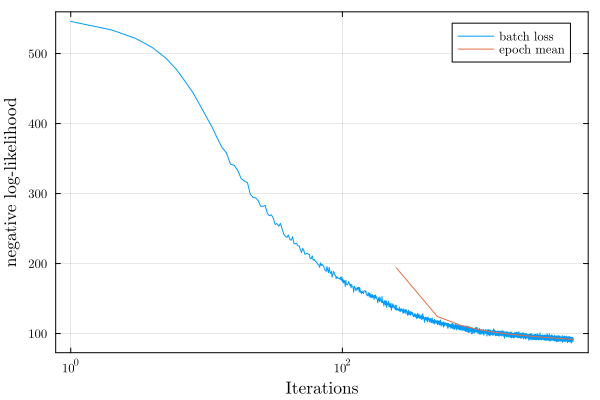

In [31]:
plot_loss(losses, length(mnist_binary_loader))

In [32]:
function _sample!(xs, model; input_order=1:(28^2))
    # xs = zeros(Bool, 28^2, n) |> device
    # model = model 
    # xs = xs 
    for d in sortperm(input_order)
        ps = σ(model(xs)[d, :])
        xs[d, :] .= rand_like(ps) .< ps
    end

    return xs 
end

_sample! (generic function with 1 method)

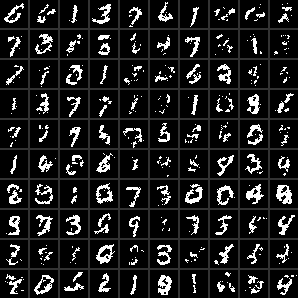

In [33]:
begin
    xs = zeros(Bool, 784, 100) |> device
    xs = _sample!(xs, made1; input_order=input_order)

    # vec2imgs(xs; nrows= 10)
    # vec2imgs(xs; nrows=10)

    vec2imgs(xs; nrows = 10)
end

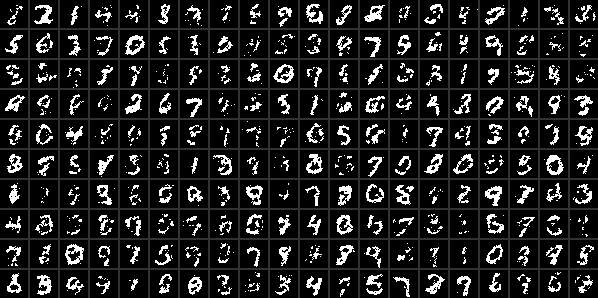

In [34]:
vec2imgs(_sample(made1, 200; input_order= input_order); nrows=10)

In [35]:
logpdf(made1, mnist_binary_test |> device)

-94.078766f0

In [36]:
begin
    Random.seed!(1234)
    hidden_size = 500
    # hidden_order = sort(rand(1:28^2-1, hidden_size))
    # hidden_order = shuffle(1:28^2-1)[1:hidden_size]
    hidden_order = rand(1:28^2-1, hidden_size)
    input_order = shuffle([1:28^2;])
    path1 = Chain(MaskedDense(28^2, hidden_size, input_order, hidden_order; act = tanh, output_layer =false), 
        MaskedDense(hidden_size, 28^2, hidden_order, input_order; act = identity,output_layer =true))

    path2 = MaskedDense(28^2, 28^2, input_order, input_order; act = identity, output_layer =true)
    made2_res = Parallel(+; path1, path2) |> device
    opt = Flux.setup(AdamW(0.001, (0.9, 0.999), 3e-4, couple=false), made2_res)
    losses2 = []


    @showprogress for epoch in 1:20
        for (xs, ) in mnist_binary_loader
            xs = xs |> device
            li, gs = Flux.withgradient(made2_res) do m
                preds = m(xs)
                sum(Flux.logitbinarycrossentropy(preds, xs; agg = identity), dims=1) |> mean
            end
            Flux.update!(opt, made2_res, gs[1])
            push!(losses2, li)
        end
    end
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:17


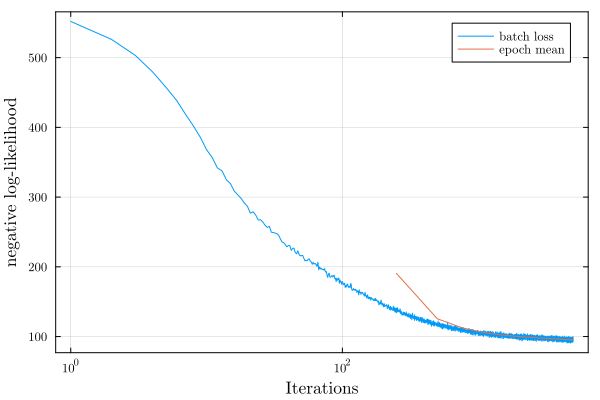

In [37]:
# plot(losses2, xscale=:log10, fmt=:svg, label="", xlabel="Epoch")
plot_loss(losses2, length(mnist_binary_loader))

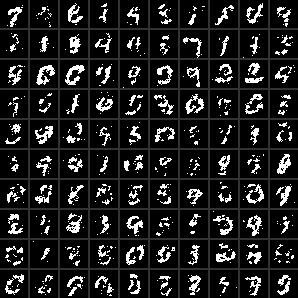

In [38]:
vec2imgs(_sample(made2_res, 100; input_order= input_order); nrows=10)